# Porównanie przebiegów symulacji

Ten notatnik uruchamia magazyn **bez GUI** (headless) i zapisuje te same dane,
które pokazuje podgląd na żywo (`src/visualization/live_stats.py::snapshot`):
serie czasowe KPI, stan robotów, stanowisk i czasów floty — plus finalne metryki
i pełną listę zamówień. Porównujemy kilka przebiegów (np. różne rozmieszczenia
przy tym samym `seed`), a dane lądują w `output/runs/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from src.experiments.build import make_warehouse, olist_stats
from src.experiments.record import run_and_record, load
from src.plotting.style import style, REAL, GENERATED, INK

style()

OUT_ROOT = ROOT / "output" / "runs"

def show_save(fig, path):
    """Save the figure and leave it open for the inline backend.

    The figure must NOT be returned: Jupyter would render the returned
    Figure object and the inline backend would render it again, showing
    every plot twice.
    """
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=150)

## 1. Konfiguracja przebiegów

Każdy przebieg to `label` (nazwa na wykresach) + `params` (te same parametry co
suwak w GUI). Ten sam `seed` przy różnych `placement`/`return_policy`/`num_robots`
oznacza identyczne zamówienia i porównanie „przy tych samych danych”.

Uwaga: `placement="ABC"` różni się od `random` dopiero przy zamówieniach Olist
(`orders="olist"`); w trybie demo każdy regał ma jeden produkt.

In [2]:
# Ten sam seed, różne rozmieszczenie produktów.
RUNS = [
    {"label": "random", "params": dict(
        layout="kiva_standard", num_robots=8, orders="olist",
        placement="random", return_policy="home", volume=1.0, hours=2, seed=1)},
    {"label": "ABC", "params": dict(
        layout="kiva_standard", num_robots=8, orders="olist",
        placement="ABC", return_policy="home", volume=1.0, hours=2, seed=1)},
]

# Szybki test bez danych Olist — porównanie strategii powrotu regału:
# RUNS = [
#     {"label": "home", "params": dict(
#         layout="kiva_standard", num_robots=8, orders="demo",
#         placement="random", return_policy="home", volume=1.0, hours=2, seed=1)},
#     {"label": "nearest", "params": dict(
#         layout="kiva_standard", num_robots=8, orders="demo",
#         placement="random", return_policy="nearest", volume=1.0, hours=2, seed=1)},
# ]

DURATION = RUNS[0]["params"]["hours"] * 3600
SAMPLE_EVERY = 10.0

if any(r["params"]["orders"] == "olist" for r in RUNS) and olist_stats() is None:
    print("UWAGA: brak danych Olist (data/raw). Pobierz: `uv run data/download_olist.py`; "
          "przy orders='demo' placement ABC == random.")

In [3]:
def collect(spec):
    rec = run_and_record(
        factory=lambda p=spec["params"]: make_warehouse(**p),
        duration=DURATION,
        sample_every=SAMPLE_EVERY,
        run_id=spec["label"],
        params=spec["params"],
    )
    rec.write_outputs(OUT_ROOT / spec["label"])
    return rec

recorded = {spec["label"]: collect(spec) for spec in RUNS}

for label, rec in recorded.items():
    m = rec.metrics
    print(f"{label}: status={rec.status}, zrealizowane={m.completed_orders}, "
          f"czas symulacji={m.simulated_time:.0f}s, wall={rec.wall_s:.1f}s")

random: status=ok, zrealizowane=94, czas symulacji=7200s, wall=0.3s
ABC: status=ok, zrealizowane=94, czas symulacji=7200s, wall=0.3s


## 2. Serie czasowe — porównanie

Każdy przebieg ma stały kolor na wszystkich wykresach (kolor = przebieg, nie
jego pozycja w rankingu).

In [4]:
HOUR = 3600.0
COLORS = [REAL, GENERATED, INK]

def snapshots_frame(recorded):
    frames = []
    for color, (label, rec) in zip(COLORS, recorded.items()):
        df = rec.snapshots_df.copy()
        df["hours"] = df["time"] / HOUR
        df["_label"] = label
        df["_color"] = color
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

snap = snapshots_frame(recorded)

def line(ax, column, ylabel, title):
    for label, grp in snap.groupby("_label", sort=False):
        ax.plot(grp["hours"], grp[column], color=grp["_color"].iloc[0], lw=2, label=label)
    ax.set_xlabel("czas (h)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()

def station_waiting(recorded):
    frames = []
    for label, rec in recorded.items():
        df = rec.stations_df.groupby("time", as_index=False)["waiting"].mean()
        df["hours"] = df["time"] / HOUR
        df["_label"] = label
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

waiting = station_waiting(recorded)

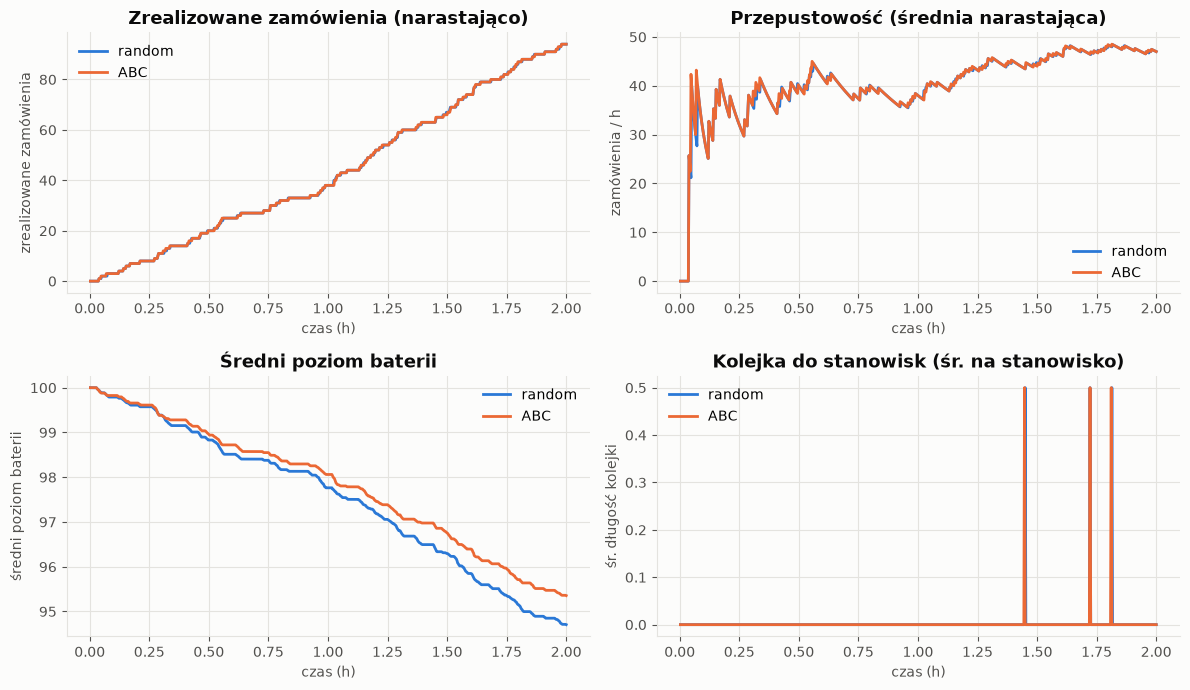

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
line(axes[0, 0], "completed", "zrealizowane zamówienia", "Zrealizowane zamówienia (narastająco)")
line(axes[0, 1], "orders_per_hour", "zamówienia / h", "Przepustowość (średnia narastająca)")
line(axes[1, 0], "battery_mean", "średni poziom baterii", "Średni poziom baterii")

ax = axes[1, 1]
for color, (label, grp) in zip(COLORS, waiting.groupby("_label", sort=False)):
    ax.plot(grp["hours"], grp["waiting"], color=color, lw=2, label=label)
ax.set_xlabel("czas (h)")
ax.set_ylabel("śr. długość kolejki")
ax.set_title("Kolejka do stanowisk (śr. na stanowisko)")
ax.legend()

show_save(fig, OUT_ROOT / "comparison_time_series.png")

## 3. Czas floty na koniec przebiegu

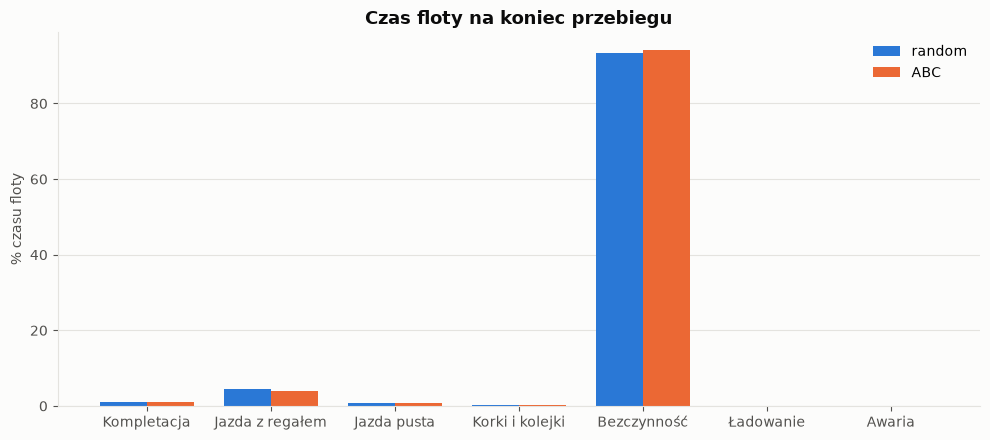

In [6]:
import numpy as np
from src.visualization.live_stats import FLEET_CATEGORIES

def fleet_shares(rec):
    last = rec.snapshots_df.iloc[-1]
    shares = {label: float(last[f"fleet_{key}"]) for key, label in FLEET_CATEGORIES}
    total = sum(shares.values()) or 1.0
    return {k: 100 * v / total for k, v in shares.items()}

shares = pd.DataFrame({label: fleet_shares(rec) for label, rec in recorded.items()})
x = np.arange(len(shares.index))
width = 0.38
offset = (len(shares.columns) - 1) / 2 * width

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, label in enumerate(shares.columns):
    ax.bar(x + (i * width - offset), shares[label], width, color=COLORS[i], label=label)
ax.set_xticks(x, shares.index)
ax.set_ylabel("% czasu floty")
ax.set_title("Czas floty na koniec przebiegu")
ax.grid(axis="x", visible=False)
ax.legend()
show_save(fig, OUT_ROOT / "comparison_fleet_time.png")

## 4. Metryki końcowe

In [7]:
def summary(recorded):
    rows = {}
    for label, rec in recorded.items():
        m = rec.metrics
        rows[label] = {
            "status": rec.status,
            "symulowane (s)": m.simulated_time,
            "zrealizowane": m.completed_orders,
            "zam./h": round(m.orders_per_hour, 2) if m.orders_per_hour is not None else None,
            "śr. realizacja (s)": round(m.average_completion_time, 1) if m.average_completion_time is not None else None,
            "najdłuższa (s)": round(m.longest_completion_time, 1) if m.longest_completion_time is not None else None,
            "śr. czek. na robota (s)": round(m.average_waiting_time, 1) if m.average_waiting_time is not None else None,
            "śr. czek. w kolejce (s)": round(m.average_station_wait, 1) if m.average_station_wait is not None else None,
            "śr. korek/robota (s)": round(m.average_traffic_wait_s, 1) if m.average_traffic_wait_s is not None else None,
        }
    return pd.DataFrame(rows).T

summary(recorded)

,status,symulowane (s),zrealizowane,zam./h,śr. realizacja (s),najdłuższa (s),śr. czek. na robota (s),śr. czek. w kolejce (s),śr. korek/robota (s)
random,ok,7200.0,94,47.0,25.5,42.9,0.5,0.2,9.5
ABC,ok,7200.0,94,47.0,23.1,37.3,0.5,0.2,8.2


## 5. Wczytanie zapisanych przebiegów

Zamiast liczyć od nowa możesz wczytać przebieg zapisany przez notatnik lub przez
`uv run runners/run_record.py`:

In [8]:
# rec = load(OUT_ROOT / "random")
# rec.snapshots_df.head()
# rec.orders_df.head()